# 02 · Bosonic operators as quantics MPOs (Sec. II B, Fig. 3, Table I)

* **Shift** $T_{n,n'}=\delta_{n+m,n'}$ is an *exact* rank-2 MPO: a binary adder whose bond carries the carry bit.
* **Annihilation** $\hat a = T\,\mathrm{diag}(\sqrt n)$: the diagonal comes from a QTT of $\sqrt n$, promoted to a diagonal MPO $B^{(i)}(\sigma,\sigma')=M^{(i)}(\sigma)\delta_{\sigma\sigma'}$.
* **Normal-ordered powers** $(\hat a^\dagger)^m \hat a^m$ are diagonal polynomials (falling factorials), exact at rank $m+1$.

In [1]:
import os, sys
from tutorial_utils import *
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(backend_banner())
PAPER_SIZE = HAVE_QTTLIND and os.environ.get("QTTLIND_PAPER_SIZE") == "1"   # published sizes (hours); default: quick mode

qttlind 2.0.0, QTT solver: quick mode (set QTTLIND_PAPER_SIZE=1 for the published sizes).


## The exact shift MPO

In [2]:
for R, m in [(4, 1), (6, 3), (8, 77)]:
    T = shift_mpo_dense(R, m)
    print(f"R={R}, m={m}: max |T - delta_(n+m,n')| = {np.abs(T - np.eye(2**R, k=m)).max()}")
W = shift_mpo(4, 1)[0]
print("site tensor W[c_left, c_right, sigma, sigma'] nonzeros:",
      [tuple(int(i) for i in idx) for idx in np.argwhere(W)])

R=4, m=1: max |T - delta_(n+m,n')| = 0.0
R=6, m=3: max |T - delta_(n+m,n')| = 0.0
R=8, m=77: max |T - delta_(n+m,n')| = 0.0
site tensor W[c_left, c_right, sigma, sigma'] nonzeros: [(0, 0, 0, 0), (0, 0, 1, 1), (0, 1, 0, 1), (1, 1, 1, 0)]


## Building $\hat a$ from the shift and a QTT of $\sqrt n$

In [3]:
R = 8; N = 2**R
sq = tt_svd(np.sqrt(np.arange(N)), R, tol=1e-28)
print("QTT ranks of sqrt(n):", tt_ranks(sq))
A = shift_mpo_dense(R, 1) @ np.diag(tt_to_dense(sq))
print("|A - a|_max =", np.abs(A - dr.destroy(N)).max())

QTT ranks of sqrt(n): [2, 4, 8, 9, 8, 4, 2]
|A - a|_max = 1.5987211554602254e-13


## Fig. 3 — error of $\hat a$ versus MPO rank $\bar\chi_q$

Two metrics, as in the paper: the normalised Frobenius distance to the exact matrix, and $|\langle\alpha|\hat a_{\rm approx}|\alpha\rangle/\alpha - 1|$ for a large coherent state $\alpha=2^{(R-1)/2}$.
Here the MPO is obtained by TT-SVD of the bit-interleaved $2^R\times 2^R$ matrix capped at rank $\bar\chi_q$ (dense route, so $R\le 10$ without the QTT solver).

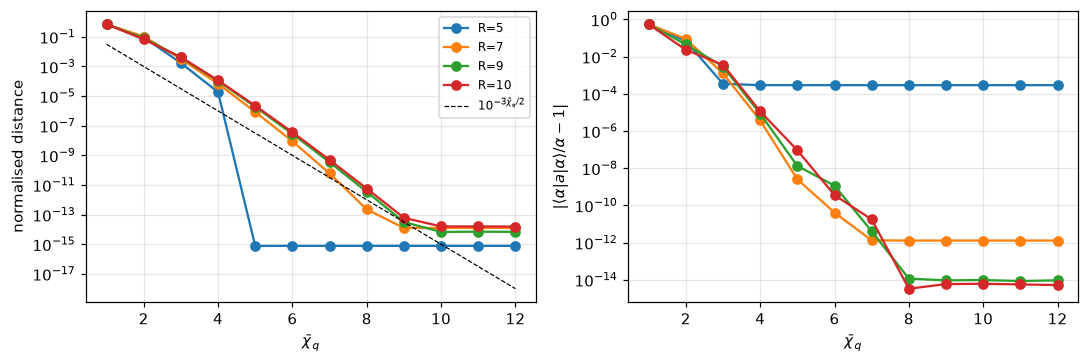

In [4]:
Rs = [5, 7, 9, 10] if not PAPER_SIZE else [6, 8, 10, 12, 14, 16]
chis = range(1, 13)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for R in Rs:
    N = 2**R; a = dr.destroy(N)
    al = 2**((R - 1) / 2); coh = dr.coherent(N, al)
    e1, e2 = [], []
    for chi in chis:
        if "mpo" in ql.FEATURES:       # qttlind.bosons.operators
            Aq = ql.bosons.operators.annihilation(R, tol=0.0, chi_max=chi).to_dense()
        else:
            Aq = mpo_to_dense(matrix_to_qtt_mpo(a, R, tol=0, chi_max=chi), R)
        e1.append(np.linalg.norm(Aq - a) / np.linalg.norm(a))
        e2.append(abs(np.vdot(coh, Aq @ coh) / al - 1))
    ax[0].semilogy(list(chis), np.maximum(e1, 1e-17), "o-", label=f"R={R}")
    ax[1].semilogy(list(chis), np.maximum(e2, 1e-17), "o-", label=f"R={R}")
c = np.array(list(chis))
ax[0].semilogy(c, 10.0**(-1.5 * c), "k--", lw=0.8, label=r"$10^{-3\bar\chi_q/2}$")
ax[0].set(xlabel=r"$\bar\chi_q$", ylabel="normalised distance"); ax[0].legend(fontsize=8)
ax[1].set(xlabel=r"$\bar\chi_q$", ylabel=r"$|\langle\alpha|a|\alpha\rangle/\alpha-1|$")
plt.tight_layout(); savefig(fig, "fig03_annihilation_mpo.png"); plt.show()

## Table I — ranks of common operators (independent of $R$)

In [5]:
def mpo_rank(M, R, tol=1e-24):   # weight 1e-24 = relative error 1e-12, Table I's precision
    if "mpo" in ql.FEATURES:       # qttlind.MPO
        return ql.MPO.from_dense(M, [2] * R, tol=tol).max_rank
    return max(tt_ranks(matrix_to_qtt_mpo(M, R, tol=tol)))

print(f"{'operator':>12} | " + " | ".join(f"R={R:2d}" for R in (6, 8, 10)))
for name, build in [("a", lambda a: a), ("a + a^dag", lambda a: a + a.T),
                    ("a^3", lambda a: np.linalg.matrix_power(a, 3)),
                    ("a^dag2 a^2", lambda a: np.linalg.matrix_power(a.T, 2) @ np.linalg.matrix_power(a, 2)),
                    ("a^dag3 a^3", lambda a: np.linalg.matrix_power(a.T, 3) @ np.linalg.matrix_power(a, 3))]:
    print(f"{name:>12} | " + " | ".join(f"{mpo_rank(build(dr.destroy(2**R).real), R):4d}" for R in (6, 8, 10)))
print("Paper: a: 8, a+a^dag: 10, a^n: 8 (all at 1e-12); a^dag^m a^m: m+1 (exact).")

    operator | R= 6 | R= 8 | R=10


           a |    8 |    9 |    9


   a + a^dag |    9 |   10 |   10


         a^3 |    8 |   10 |   10


  a^dag2 a^2 |    3 |    3 |    3


  a^dag3 a^3 |    4 |    4 |    4
Paper: a: 8, a+a^dag: 10, a^n: 8 (all at 1e-12); a^dag^m a^m: m+1 (exact).


**Note.** For $(\hat a^\dagger)^m\hat a^m$ the TT-SVD at $10^{-12}$ returns exactly $m+1$: the falling factorial $n(n-1)\cdots(n-m+1)$ is a degree-$m$ polynomial, and polynomials of degree $m$ have exact quantics rank $m+1$.